In [2]:
import numpy as np
import networkx as nx

print("NumPy:", np.__version__)
print("NetworkX:", nx.__version__)
print("Everything is working!")

NumPy: 2.3.5
NetworkX: 3.5
Everything is working!


In [3]:
G = nx.Graph()

edges = [
    (0, 1, 4),
    (0, 2, 2),
    (1, 2, 1),
    (1, 3, 5),
    (2, 3, 8),
    (2, 4, 10),
    (3, 4, 2),
    (3, 5, 6),
    (4, 5, 3),
    (4, 6, 7),
    (5, 7, 4),
    (6, 7, 1),
    (6, 8, 5),
    (7, 8, 2),
    (7, 9, 6),
    (8, 9, 3)
]

G.add_weighted_edges_from(edges)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 10
Number of edges: 16


In [18]:
DEPOT = 0

DESTINATIONS = [1, 2, 3, 4, 5, 6, 7, 8]

NUM_DESTINATIONS = len(DESTINATIONS)

NUM_VEHICLES = 5

print("Depot:", DEPOT)
print("Destinations:", DESTINATIONS)

Depot: 0
Destinations: [1, 2, 3, 4, 5, 6, 7, 8]


In [5]:
def route_distance(route, graph):
    total_distance = 0

    for i in range(len(route) - 1):
        start = route[i]
        end = route[i + 1]

        try:
            distance = nx.shortest_path_length(
                graph,
                source=start,
                target=end,
                weight="weight"
            )
            total_distance += distance

        except nx.NetworkXNoPath:
            return float("inf")

    return total_distance

In [6]:
test_route = [0, 1, 2, 3, 4, 0]

distance = route_distance(test_route, G)

print("Test route:", test_route)
print("Distance:", distance)

Test route: [0, 1, 2, 3, 4, 0]
Distance: 22


In [7]:
def particle_to_route(position, destinations):
    order = np.argsort(position)

    ordered_destinations = [
        destinations[i] for i in order
    ]

    return [DEPOT] + ordered_destinations + [DEPOT]

In [8]:
position = np.array([0.72, 0.13, 0.91, 0.45])

route = particle_to_route(position, DESTINATIONS)

print("Particle:", position)
print("Route:", route)
print("Distance:", route_distance(route, G))

Particle: [0.72 0.13 0.91 0.45]
Route: [0, 2, 4, 1, 3, 0]
Distance: 30


In [9]:
def fitness(position, graph, destinations):
    route = particle_to_route(position, destinations)
    distance = route_distance(route, graph)

    return distance

position = np.random.rand(len(DESTINATIONS))

print("Position:", position)
print("Fitness:", fitness(position, G, DESTINATIONS))

Position: [0.18223694 0.46247858 0.92732548 0.05078033]
Fitness: 32


In [10]:
# PSO parameters

NUM_PARTICLES = 20
MAX_ITERATIONS = 100

W = 0.7          # inertia
C1 = 1.5         # personal best influence
C2 = 1.5         # global best influence

NUM_DESTINATIONS = len(DESTINATIONS)

print("Particles:", NUM_PARTICLES)
print("Iterations:", MAX_ITERATIONS)

Particles: 20
Iterations: 100


In [11]:
positions = np.random.rand(NUM_PARTICLES, NUM_DESTINATIONS)

velocities = np.zeros((NUM_PARTICLES, NUM_DESTINATIONS))

print("Position shape:", positions.shape)
print("Velocity shape:", velocities.shape)
print("\nFirst particle:", positions[0])

Position shape: (20, 4)
Velocity shape: (20, 4)

First particle: [0.25735921 0.59015252 0.77317993 0.11353773]


In [12]:
pbest_positions = positions.copy()

pbest_fitness = np.array([
    fitness(position, G, DESTINATIONS)
    for position in positions
])

print("Personal best fitness:")
print(pbest_fitness)

Personal best fitness:
[32 30 20 32 22 32 32 30 32 20 32 22 32 22 30 22 22 32 30 32]


In [13]:
best_particle_index = np.argmin(pbest_fitness)

gbest_position = pbest_positions[best_particle_index].copy()
gbest_fitness = pbest_fitness[best_particle_index]

print("Global best position:", gbest_position)
print("Global best fitness:", gbest_fitness)

Global best position: [0.71723462 0.99938942 0.39036543 0.32089517]
Global best fitness: 20


In [14]:
for iteration in range(MAX_ITERATIONS):

    for i in range(NUM_PARTICLES):

        r1 = np.random.rand(NUM_DESTINATIONS)
        r2 = np.random.rand(NUM_DESTINATIONS)

        velocities[i] = (
            W * velocities[i]
            + C1 * r1 * (pbest_positions[i] - positions[i])
            + C2 * r2 * (gbest_position - positions[i])
        )

        positions[i] = positions[i] + velocities[i]

        # Keep values inside [0, 1]
        positions[i] = np.clip(positions[i], 0, 1)

        current_fitness = fitness(
            positions[i],
            G,
            DESTINATIONS
        )

        # Update personal best
        if current_fitness < pbest_fitness[i]:
            pbest_positions[i] = positions[i].copy()
            pbest_fitness[i] = current_fitness

            # Update global best
            if current_fitness < gbest_fitness:
                gbest_position = positions[i].copy()
                gbest_fitness = current_fitness

    if iteration % 10 == 0:
        print(
            f"Iteration {iteration}: "
            f"Best fitness = {gbest_fitness}"
        )

Iteration 0: Best fitness = 20
Iteration 10: Best fitness = 20
Iteration 20: Best fitness = 20
Iteration 30: Best fitness = 20
Iteration 40: Best fitness = 20
Iteration 50: Best fitness = 20
Iteration 60: Best fitness = 20
Iteration 70: Best fitness = 20
Iteration 80: Best fitness = 20
Iteration 90: Best fitness = 20


In [15]:
best_route = particle_to_route(
    gbest_position,
    DESTINATIONS
)

print("Best particle:", gbest_position)
print("Best route:", best_route)
print("Best distance:", gbest_fitness)

Best particle: [0.71723462 0.99938942 0.39036543 0.32089517]
Best route: [0, 4, 3, 1, 2, 0]
Best distance: 20


In [16]:
# ==========================================
# QPSO - Quantum Particle Swarm Optimization
# ==========================================

# QPSO parameter
BETA_MAX = 1.0
BETA_MIN = 0.5

# Re-initialize particles for a fresh QPSO run
positions = np.random.rand(NUM_PARTICLES, NUM_DESTINATIONS)

# Personal best
pbest_positions = positions.copy()

pbest_fitness = np.array([
    fitness(position, G, DESTINATIONS)
    for position in positions
])

# Global best
best_particle_index = np.argmin(pbest_fitness)

gbest_position = pbest_positions[best_particle_index].copy()
gbest_fitness = pbest_fitness[best_particle_index]

# Store convergence history
qpso_convergence = []

# ==========================================
# QPSO ITERATIONS
# ==========================================

for iteration in range(MAX_ITERATIONS):

    # Linearly decrease beta
    beta_qpso = (
        BETA_MAX
        - (BETA_MAX - BETA_MIN)
        * iteration / MAX_ITERATIONS
    )

    # --------------------------------------
    # MBEST = Mean Best Position
    # --------------------------------------
    mbest = np.mean(pbest_positions, axis=0)

    # Update every particle
    for i in range(NUM_PARTICLES):

        # Random value for attractor
        phi = np.random.rand(NUM_DESTINATIONS)

        # Attractor position
        p = (
            phi * pbest_positions[i]
            + (1 - phi) * gbest_position
        )

        # Random number for logarithmic term
        u = np.random.rand(NUM_DESTINATIONS)

        # Randomly choose +1 or -1
        sign = np.where(
            np.random.rand(NUM_DESTINATIONS) < 0.5,
            1,
            -1
        )

        # --------------------------------------
        # QUANTUM POSITION UPDATE
        # X(t+1) =
        # p ± beta * |MBEST - X(t)| * ln(1/u)
        # --------------------------------------

        positions[i] = (
            p
            + sign
            * beta_qpso
            * np.abs(mbest - positions[i])
            * np.log(1 / u)
        )

        # Keep positions inside [0, 1]
        positions[i] = np.clip(
            positions[i],
            0,
            1
        )

        # Calculate new fitness
        current_fitness = fitness(
            positions[i],
            G,
            DESTINATIONS
        )

        # --------------------------------------
        # Update Personal Best
        # --------------------------------------

        if current_fitness < pbest_fitness[i]:

            pbest_fitness[i] = current_fitness
            pbest_positions[i] = positions[i].copy()

        # --------------------------------------
        # Update Global Best
        # --------------------------------------

        if current_fitness < gbest_fitness:

            gbest_fitness = current_fitness
            gbest_position = positions[i].copy()

    # Save best fitness for convergence graph
    qpso_convergence.append(gbest_fitness)

    # Print progress
    if iteration % 10 == 0:
        print(
            f"Iteration {iteration}: "
            f"Best Distance = {gbest_fitness}"
        )


# ==========================================
# FINAL RESULT
# ==========================================

best_route = particle_to_route(
    gbest_position,
    DESTINATIONS
)

print("\n========== QPSO RESULT ==========")
print("Best particle:", gbest_position)
print("Best route:", best_route)
print("Best distance:", gbest_fitness)

Iteration 0: Best Distance = 20
Iteration 10: Best Distance = 20
Iteration 20: Best Distance = 20
Iteration 30: Best Distance = 20
Iteration 40: Best Distance = 20
Iteration 50: Best Distance = 20
Iteration 60: Best Distance = 20
Iteration 70: Best Distance = 20
Iteration 80: Best Distance = 20
Iteration 90: Best Distance = 20

========== QPSO RESULT ==========
Best particle: [0.05213541 0.02834437 0.29852839 0.08000263]
Best route: [0, 2, 1, 4, 3, 0]
Best distance: 20


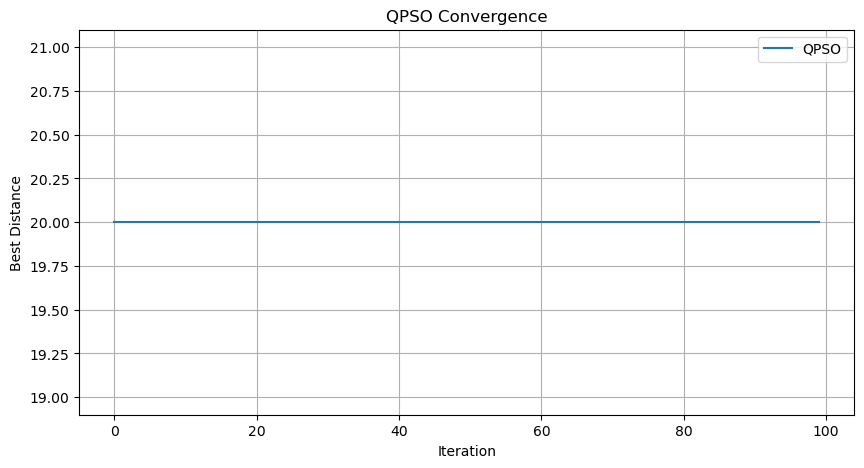

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(len(qpso_convergence)),
    qpso_convergence,
    label="QPSO"
)

plt.xlabel("Iteration")
plt.ylabel("Best Distance")
plt.title("QPSO Convergence")
plt.legend()
plt.grid(True)

plt.show()

In [107]:
# ==============================
# PARTICLE -> MULTI-VEHICLE ROUTES
# ==============================

def particle_to_routes(position, destinations, num_vehicles, depot=0):
    
    n = len(destinations)

    # First n values → destination ordering
    order_values = position[:n]

    # Next n values → vehicle assignment
    vehicle_values = position[n:2*n]

    # SPV: sort destinations according to order values
    sorted_indices = np.argsort(order_values)

    # Convert vehicle values into vehicle numbers
    assignments = np.floor(
        vehicle_values * num_vehicles
    ).astype(int)

    assignments = np.clip(
        assignments,
        0,
        num_vehicles - 1
    )

    # Create empty routes
    routes = [[] for _ in range(num_vehicles)]

    # Add destinations in SPV order
    for idx in sorted_indices:
        destination = destinations[idx]
        vehicle_index = assignments[idx]
        routes[vehicle_index].append(destination)

    # Add depot at beginning and end
    final_routes = []

    for route in routes:
        if len(route) > 0:
            final_route = [depot] + route + [depot]
        else:
            final_route = [depot]
        
        final_routes.append(final_route)

    return final_routes

In [20]:
test_position = np.random.rand(NUM_DESTINATIONS)

routes = particle_to_routes(
    test_position,
    DESTINATIONS,
    NUM_VEHICLES
)

print("Particle:")
print(test_position)

print("\nVehicle routes:")

for i, route in enumerate(routes):
    print(f"Vehicle {i+1}: {route}")

Particle:
[0.79706872 0.64877569 0.62011801 0.82474358 0.60586556 0.98331258
 0.49535398 0.71244779]

Vehicle routes:
Vehicle 1: [0, 7, 1, 0]
Vehicle 2: [0, 5, 4, 0]
Vehicle 3: [0, 3, 6, 0]
Vehicle 4: [0, 2, 0]
Vehicle 5: [0, 8, 0]


In [21]:
# ==============================
# MULTI-VEHICLE FITNESS
# ==============================

def route_distance(route, graph):
    
    total_distance = 0
    
    for i in range(len(route) - 1):
        
        try:
            distance = nx.shortest_path_length(
                graph,
                route[i],
                route[i + 1],
                weight="weight"
            )
            
            total_distance += distance
            
        except nx.NetworkXNoPath:
            return float("inf")
    
    return total_distance


def multi_vehicle_fitness(
    position,
    graph,
    destinations,
    num_vehicles
):
    
    routes = particle_to_routes(
        position,
        destinations,
        num_vehicles
    )
    
    total_distance = 0
    
    for route in routes:
        
        distance = route_distance(route, graph)
        
        if distance == float("inf"):
            return float("inf")
        
        total_distance += distance
    
    return total_distance

In [22]:
test_position = np.random.rand(NUM_DESTINATIONS)

routes = particle_to_routes(
    test_position,
    DESTINATIONS,
    NUM_VEHICLES
)

fitness_value = multi_vehicle_fitness(
    test_position,
    G,
    DESTINATIONS,
    NUM_VEHICLES
)

print("Routes:")

for i, route in enumerate(routes):
    print(f"Vehicle {i+1}: {route}")

print("\nTotal fleet distance:", fitness_value)

Routes:
Vehicle 1: [0, 3, 2, 0]
Vehicle 2: [0, 4, 6, 0]
Vehicle 3: [0, 1, 8, 0]
Vehicle 4: [0, 5, 0]
Vehicle 5: [0, 7, 0]

Total fleet distance: 148


In [23]:
# ==============================
# MULTI-VEHICLE PSO
# ==============================

NUM_PARTICLES = 20
MAX_ITERATIONS = 100

W = 0.7
C1 = 1.5
C2 = 1.5

positions = np.random.rand(
    NUM_PARTICLES,
    NUM_DESTINATIONS
)

velocities = np.zeros(
    (NUM_PARTICLES, NUM_DESTINATIONS)
)

# Personal best
pbest_positions = positions.copy()

pbest_fitness = np.array([
    multi_vehicle_fitness(
        position,
        G,
        DESTINATIONS,
        NUM_VEHICLES
    )
    for position in positions
])

# Global best
best_particle_index = np.argmin(pbest_fitness)

gbest_position = pbest_positions[
    best_particle_index
].copy()

gbest_fitness = pbest_fitness[
    best_particle_index
]

pso_convergence = []

for iteration in range(MAX_ITERATIONS):
    
    for i in range(NUM_PARTICLES):
        
        r1 = np.random.rand(NUM_DESTINATIONS)
        r2 = np.random.rand(NUM_DESTINATIONS)
        
        velocities[i] = (
            W * velocities[i]
            + C1 * r1 * (
                pbest_positions[i] - positions[i]
            )
            + C2 * r2 * (
                gbest_position - positions[i]
            )
        )
        
        positions[i] += velocities[i]
        
        positions[i] = np.clip(
            positions[i],
            0,
            1
        )
        
        current_fitness = multi_vehicle_fitness(
            positions[i],
            G,
            DESTINATIONS,
            NUM_VEHICLES
        )
        
        if current_fitness < pbest_fitness[i]:
            
            pbest_fitness[i] = current_fitness
            
            pbest_positions[i] = positions[i].copy()
            
            if current_fitness < gbest_fitness:
                
                gbest_fitness = current_fitness
                
                gbest_position = positions[i].copy()
    
    pso_convergence.append(gbest_fitness)
    
    if iteration % 10 == 0:
        print(
            f"Iteration {iteration}: "
            f"Best Fleet Distance = {gbest_fitness}"
        )

print("\n==============================")
print("FINAL PSO RESULT")
print("==============================")

best_routes = particle_to_routes(
    gbest_position,
    DESTINATIONS,
    NUM_VEHICLES
)

for i, route in enumerate(best_routes):
    print(f"Vehicle {i+1}: {route}")

print("\nBest fleet distance:", gbest_fitness)

Iteration 0: Best Fleet Distance = 115
Iteration 10: Best Fleet Distance = 103
Iteration 20: Best Fleet Distance = 103
Iteration 30: Best Fleet Distance = 103
Iteration 40: Best Fleet Distance = 103
Iteration 50: Best Fleet Distance = 103
Iteration 60: Best Fleet Distance = 103
Iteration 70: Best Fleet Distance = 103
Iteration 80: Best Fleet Distance = 103
Iteration 90: Best Fleet Distance = 103

FINAL PSO RESULT
Vehicle 1: [0, 7, 6, 0]
Vehicle 2: [0, 4, 3, 0]
Vehicle 3: [0, 8, 5, 0]
Vehicle 4: [0, 1, 0]
Vehicle 5: [0, 2, 0]

Best fleet distance: 103


In [24]:
# ==============================
# MULTI-VEHICLE QPSO
# ==============================

NUM_PARTICLES = 25
MAX_ITERATIONS = 150

BETA_MAX = 1.0
BETA_MIN = 0.5

positions = np.random.rand(
    NUM_PARTICLES,
    NUM_DESTINATIONS
)

# Personal best
pbest_positions = positions.copy()

pbest_fitness = np.array([
    multi_vehicle_fitness(
        position,
        G,
        DESTINATIONS,
        NUM_VEHICLES
    )
    for position in positions
])

# Global best
best_particle_index = np.argmin(pbest_fitness)

gbest_position = pbest_positions[
    best_particle_index
].copy()

gbest_fitness = pbest_fitness[
    best_particle_index
]

qpso_convergence = []

for iteration in range(MAX_ITERATIONS):
    
    # --------------------------------
    # Beta schedule
    # --------------------------------
    
    beta_qpso = (
        BETA_MAX
        - (BETA_MAX - BETA_MIN)
        * iteration
        / MAX_ITERATIONS
    )
    
    # --------------------------------
    # MBEST
    # --------------------------------
    
    mbest = np.mean(
        pbest_positions,
        axis=0
    )
    
    for i in range(NUM_PARTICLES):
        
        # --------------------------------
        # Attractor
        # --------------------------------
        
        phi = np.random.rand(
            NUM_DESTINATIONS
        )
        
        attractor = (
            phi * pbest_positions[i]
            + (1 - phi) * gbest_position
        )
        
        # --------------------------------
        # Random number
        # --------------------------------
        
        u = np.random.rand(
            NUM_DESTINATIONS
        )
        
        u = np.maximum(u, 1e-10)
        
        # --------------------------------
        # Random direction
        # --------------------------------
        
        direction = np.where(
            np.random.rand(NUM_DESTINATIONS) < 0.5,
            -1,
            1
        )
        
        # --------------------------------
        # Quantum position update
        # --------------------------------
        
        positions[i] = (
            attractor
            + direction
            * beta_qpso
            * np.abs(
                mbest - positions[i]
            )
            * np.log(1 / u)
        )
        
        # Keep position inside search space
        positions[i] = np.clip(
            positions[i],
            0,
            1
        )
        
        # --------------------------------
        # Evaluate
        # --------------------------------
        
        current_fitness = multi_vehicle_fitness(
            positions[i],
            G,
            DESTINATIONS,
            NUM_VEHICLES
        )
        
        # --------------------------------
        # Update PBest
        # --------------------------------
        
        if current_fitness < pbest_fitness[i]:
            
            pbest_fitness[i] = current_fitness
            
            pbest_positions[i] = positions[i].copy()
        
        # --------------------------------
        # Update GBest
        # --------------------------------
        
        if current_fitness < gbest_fitness:
            
            gbest_fitness = current_fitness
            
            gbest_position = positions[i].copy()
    
    qpso_convergence.append(gbest_fitness)
    
    if iteration % 10 == 0:
        print(
            f"Iteration {iteration}: "
            f"Best Fleet Distance = {gbest_fitness}"
        )

print("\n==============================")
print("FINAL QPSO RESULT")
print("==============================")

best_routes = particle_to_routes(
    gbest_position,
    DESTINATIONS,
    NUM_VEHICLES
)

for i, route in enumerate(best_routes):
    print(f"Vehicle {i+1}: {route}")

print("\nBest fleet distance:", gbest_fitness)

Iteration 0: Best Fleet Distance = 109
Iteration 10: Best Fleet Distance = 103
Iteration 20: Best Fleet Distance = 103
Iteration 30: Best Fleet Distance = 103
Iteration 40: Best Fleet Distance = 103
Iteration 50: Best Fleet Distance = 103
Iteration 60: Best Fleet Distance = 103
Iteration 70: Best Fleet Distance = 103
Iteration 80: Best Fleet Distance = 103
Iteration 90: Best Fleet Distance = 103
Iteration 100: Best Fleet Distance = 103
Iteration 110: Best Fleet Distance = 103
Iteration 120: Best Fleet Distance = 103
Iteration 130: Best Fleet Distance = 103
Iteration 140: Best Fleet Distance = 103

FINAL QPSO RESULT
Vehicle 1: [0, 3, 4, 0]
Vehicle 2: [0, 5, 6, 0]
Vehicle 3: [0, 8, 7, 0]
Vehicle 4: [0, 2, 0]
Vehicle 5: [0, 1, 0]

Best fleet distance: 103


In [26]:
# ==========================================
# QPSO DIAGNOSTIC VERSION
# ==========================================

NUM_PARTICLES = 25
MAX_ITERATIONS = 150

BETA_MAX = 1.0
BETA_MIN = 0.5

positions = np.random.rand(
    NUM_PARTICLES,
    NUM_DESTINATIONS
)

pbest_positions = positions.copy()

pbest_fitness = np.array([
    multi_vehicle_fitness(
        position,
        G,
        DESTINATIONS,
        NUM_VEHICLES
    )
    for position in positions
])

best_idx = np.argmin(pbest_fitness)

gbest_position = pbest_positions[best_idx].copy()
gbest_fitness = pbest_fitness[best_idx]

qpso_convergence = []

# Diagnostics
position_changes = []
unique_routes_per_iteration = []

for iteration in range(MAX_ITERATIONS):

    # --------------------------------------
    # Dynamic quantum contraction coefficient
    # --------------------------------------

    beta_qpso = (
        BETA_MAX
        - (BETA_MAX - BETA_MIN)
        * iteration
        / (MAX_ITERATIONS - 1)
    )

    # --------------------------------------
    # MBEST
    # --------------------------------------

    mbest = np.mean(
        pbest_positions,
        axis=0
    )

    iteration_position_change = 0

    iteration_routes = set()

    for i in range(NUM_PARTICLES):

        old_position = positions[i].copy()

        # --------------------------------------
        # Random attractor
        # --------------------------------------

        phi = np.random.rand(NUM_DESTINATIONS)

        attractor = (
            phi * pbest_positions[i]
            + (1 - phi) * gbest_position
        )

        # --------------------------------------
        # Quantum random variable
        # --------------------------------------

        u = np.random.rand(NUM_DESTINATIONS)

        u = np.clip(u, 1e-10, 1.0)

        # --------------------------------------
        # Random quantum direction
        # --------------------------------------

        sign = np.where(
            np.random.rand(NUM_DESTINATIONS) < 0.5,
            -1,
            1
        )

        # --------------------------------------
        # ACTUAL QPSO UPDATE
        # --------------------------------------

        positions[i] = (
            attractor
            + sign
            * beta_qpso
            * np.abs(mbest - positions[i])
            * np.log(1 / u)
        )

        positions[i] = np.clip(
            positions[i],
            0,
            1
        )

        # --------------------------------------
        # Measure particle movement
        # --------------------------------------

        iteration_position_change += np.linalg.norm(
            positions[i] - old_position
        )

        # --------------------------------------
        # Fitness
        # --------------------------------------

        current_fitness = multi_vehicle_fitness(
            positions[i],
            G,
            DESTINATIONS,
            NUM_VEHICLES
        )

        # --------------------------------------
        # PBest
        # --------------------------------------

        if current_fitness < pbest_fitness[i]:

            pbest_fitness[i] = current_fitness
            pbest_positions[i] = positions[i].copy()

        # --------------------------------------
        # GBest
        # --------------------------------------

        if pbest_fitness[i] < gbest_fitness:

            gbest_fitness = pbest_fitness[i]
            gbest_position = pbest_positions[i].copy()

        # --------------------------------------
        # Record route
        # --------------------------------------

        route = particle_to_routes(
            positions[i],
            DESTINATIONS,
            NUM_VEHICLES
        )

        iteration_routes.add(
            tuple(tuple(r) for r in route)
        )

    qpso_convergence.append(gbest_fitness)

    position_changes.append(
        iteration_position_change
    )

    unique_routes_per_iteration.append(
        len(iteration_routes)
    )

    if iteration % 10 == 0:

        print(
            f"Iteration {iteration:3d} | "
            f"Beta = {beta_qpso:.3f} | "
            f"Best = {gbest_fitness} | "
            f"Movement = {iteration_position_change:.4f} | "
            f"Unique routes = {len(iteration_routes)}"
        )


print("\n==============================")
print("FINAL QPSO RESULT")
print("==============================")

best_routes = particle_to_routes(
    gbest_position,
    DESTINATIONS,
    NUM_VEHICLES
)

for i, route in enumerate(best_routes):
    print(f"Vehicle {i+1}: {route}")

print("\nBest fleet distance:", gbest_fitness)

Iteration   0 | Beta = 1.000 | Best = 103 | Movement = 25.3652 | Unique routes = 25
Iteration  10 | Beta = 0.966 | Best = 103 | Movement = 17.0496 | Unique routes = 25
Iteration  20 | Beta = 0.933 | Best = 103 | Movement = 13.2646 | Unique routes = 25
Iteration  30 | Beta = 0.899 | Best = 103 | Movement = 13.0696 | Unique routes = 24
Iteration  40 | Beta = 0.866 | Best = 103 | Movement = 13.0079 | Unique routes = 24
Iteration  50 | Beta = 0.832 | Best = 103 | Movement = 13.0460 | Unique routes = 24
Iteration  60 | Beta = 0.799 | Best = 103 | Movement = 14.3624 | Unique routes = 25
Iteration  70 | Beta = 0.765 | Best = 103 | Movement = 12.2948 | Unique routes = 24
Iteration  80 | Beta = 0.732 | Best = 103 | Movement = 9.2935 | Unique routes = 22
Iteration  90 | Beta = 0.698 | Best = 103 | Movement = 9.2759 | Unique routes = 22
Iteration 100 | Beta = 0.664 | Best = 103 | Movement = 8.4563 | Unique routes = 17
Iteration 110 | Beta = 0.631 | Best = 103 | Movement = 8.8343 | Unique routes =

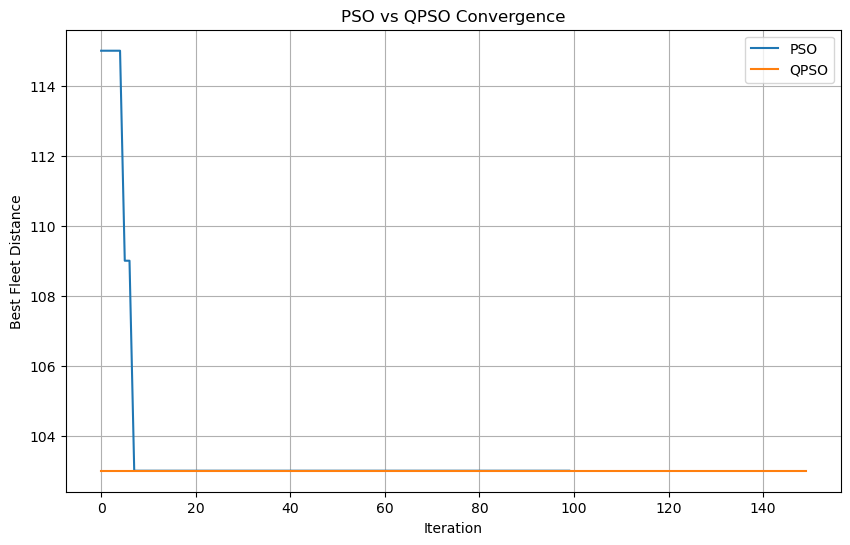

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    pso_convergence,
    label="PSO"
)

plt.plot(
    qpso_convergence,
    label="QPSO"
)

plt.xlabel("Iteration")
plt.ylabel("Best Fleet Distance")
plt.title("PSO vs QPSO Convergence")

plt.legend()
plt.grid(True)

plt.show()

In [28]:
# ==========================================
# NEW PARTICLE REPRESENTATION
# ==========================================

NUM_DESTINATIONS = 8
NUM_VEHICLES = 5

# 8 values for ordering
# 8 values for vehicle assignment
DIMENSION = NUM_DESTINATIONS * 2

print("Number of destinations:", NUM_DESTINATIONS)
print("Number of vehicles:", NUM_VEHICLES)
print("Particle dimension:", DIMENSION)

Number of destinations: 8
Number of vehicles: 5
Particle dimension: 16


In [30]:
# ==========================================
# PARTICLE -> 5 VEHICLE ROUTES
# ==========================================

def particle_to_routes(position, destinations, num_vehicles, depot=0):

    n = len(destinations)

    # --------------------------------------
    # Part 1: Ordering information
    # --------------------------------------

    order_values = position[:n]

    # --------------------------------------
    # Part 2: Vehicle assignment information
    # --------------------------------------

    vehicle_values = position[n:2*n]

    # --------------------------------------
    # SPV ordering
    # --------------------------------------

    sorted_indices = np.argsort(order_values)

    # --------------------------------------
    # Initial vehicle assignment
    # --------------------------------------

    assignments = np.floor(
        vehicle_values * num_vehicles
    ).astype(int)

    # Make sure values stay within 0 ... num_vehicles-1
    assignments = np.clip(
        assignments,
        0,
        num_vehicles - 1
    )

    # --------------------------------------
    # Make sure every vehicle gets a stop
    # --------------------------------------

    for vehicle in range(num_vehicles):

        if vehicle not in assignments:

            # Find vehicle having the most stops
            counts = np.bincount(
                assignments,
                minlength=num_vehicles
            )

            donor = np.argmax(counts)

            # Don't take the last stop from donor
            donor_indices = np.where(
                assignments == donor
            )[0]

            if len(donor_indices) > 1:

                destination_index = donor_indices[-1]

                assignments[destination_index] = vehicle

    # --------------------------------------
    # Create routes
    # --------------------------------------

    routes = [[] for _ in range(num_vehicles)]

    # Follow SPV ordering
    for idx in sorted_indices:

        vehicle = assignments[idx]

        destination = destinations[idx]

        routes[vehicle].append(destination)

    # --------------------------------------
    # Add depot
    # --          if len(donor_indices) > 1:

                destination_index = donor_indices[-1]

                assignments[destination_index] = vehicle

    # --------------------------------------
    # Create routes
    # --------------------------------------

    routes = [[] for _ in range(num_vehicles)]

    # Follow SPV ordering
    for idx in sorted_indices:

        vehicle = assignments[idx]

        destination = destinations[idx]

        routes[vehicle].append(destination)

    # --------------------------------------
    # Add ------------------------------------

    final_routes = []

    for route in routes:

        if len(route) > 0:
            final_route = [depot] + route + [depot]
        else:
            final_route = [depot, depot]

        final_routes.append(final_route)

    return final_routes

In [31]:
# ==========================================
# TEST NEW ROUTE REPRESENTATION
# ==========================================

test_position = np.random.rand(DIMENSION)

routes = particle_to_routes(
    test_position,
    DESTINATIONS,
    NUM_VEHICLES
)

print("Particle:")
print(test_position)

print("\nVehicle routes:")

for i, route in enumerate(routes):

    print(f"Vehicle {i+1}: {route}")

Particle:
[0.95445045 0.01732358 0.93409123 0.06531331 0.08567894 0.2242193
 0.7482123  0.67018375 0.69957227 0.2109807  0.37301403 0.21995252
 0.12140202 0.08636675 0.350552   0.82161429]

Vehicle routes:
Vehicle 1: [0, 5, 6, 0]
Vehicle 2: [0, 2, 4, 3, 0]
Vehicle 3: [0, 7, 0]
Vehicle 4: [0, 1, 0]
Vehicle 5: [0, 8, 0]


In [32]:
# ==========================================
# MULTI-VEHICLE FITNESS
# ==========================================

def multi_vehicle_fitness(
    position,
    graph,
    destinations,
    num_vehicles
):

    routes = particle_to_routes(
        position,
        destinations,
        num_vehicles
    )

    total_distance = 0

    for route in routes:

        # Ignore empty route
        if len(route) <= 2:
            continue

        distance = route_distance(
            route,
            graph
        )

        if distance == float("inf"):
            return float("inf")

        total_distance += distance

    return total_distance

In [33]:
test_position = np.random.rand(DIMENSION)

routes = particle_to_routes(
    test_position,
    DESTINATIONS,
    NUM_VEHICLES
)

fitness_value = multi_vehicle_fitness(
    test_position,
    G,
    DESTINATIONS,
    NUM_VEHICLES
)

print("Routes:")

for i, route in enumerate(routes):
    print(f"Vehicle {i+1}: {route}")

print("\nTotal fleet distance:", fitness_value)

Routes:
Vehicle 1: [0, 5, 0]
Vehicle 2: [0, 2, 1, 0]
Vehicle 3: [0, 8, 0]
Vehicle 4: [0, 6, 3, 0]
Vehicle 5: [0, 7, 4, 0]

Total fleet distance: 138


In [34]:
# ==========================================
# QPSO - 16 DIMENSION
# ==========================================

NUM_PARTICLES = 25
MAX_ITERATIONS = 150

BETA_MAX = 1.0
BETA_MIN = 0.5

# ------------------------------------------
# Initialize 16-dimensional particles
# ------------------------------------------

positions = np.random.rand(
    NUM_PARTICLES,
    DIMENSION
)

# ------------------------------------------
# Personal best
# ------------------------------------------

pbest_positions = positions.copy()

pbest_fitness = np.array([
    multi_vehicle_fitness(
        position,
        G,
        DESTINATIONS,
        NUM_VEHICLES
    )
    for position in positions
])

# ------------------------------------------
# Global best
# ------------------------------------------

best_idx = np.argmin(pbest_fitness)

gbest_position = pbest_positions[
    best_idx
].copy()

gbest_fitness = pbest_fitness[
    best_idx
]

# ------------------------------------------
# Convergence
# ------------------------------------------

qpso_convergence = []

# ------------------------------------------
# Main QPSO loop
# ------------------------------------------

for iteration in range(MAX_ITERATIONS):

    # --------------------------------------
    # Beta schedule
    # --------------------------------------

    beta_qpso = (
        BETA_MAX
        - (BETA_MAX - BETA_MIN)
        * iteration
        / (MAX_ITERATIONS - 1)
    )

    # --------------------------------------
    # MBEST
    # --------------------------------------

    mbest = np.mean(
        pbest_positions,
        axis=0
    )

    # --------------------------------------
    # Update every particle
    # --------------------------------------

    for i in range(NUM_PARTICLES):

        # Random attractor coefficient
        phi = np.random.rand(DIMENSION)

        attractor = (
            phi * pbest_positions[i]
            + (1 - phi) * gbest_position
        )

        # Random number
        u = np.random.rand(DIMENSION)

        u = np.clip(
            u,
            1e-10,
            1.0
        )

        # Random direction
        direction = np.where(
            np.random.rand(DIMENSION) < 0.5,
            -1,
            1
        )

        # ----------------------------------
        # QUANTUM POSITION UPDATE
        # ----------------------------------

        positions[i] = (
            attractor
            + direction
            * beta_qpso
            * np.abs(
                mbest - positions[i]
            )
            * np.log(1 / u)
        )

        # Keep values in [0,1]
        positions[i] = np.clip(
            positions[i],
            0,
            1
        )

        # ----------------------------------
        # Evaluate
        # ----------------------------------

        current_fitness = multi_vehicle_fitness(
            positions[i],
            G,
            DESTINATIONS,
            NUM_VEHICLES
        )

        # ----------------------------------
        # Update PBest
        # ----------------------------------

        if current_fitness < pbest_fitness[i]:

            pbest_fitness[i] = current_fitness

            pbest_positions[i] = positions[i].copy()

        # ----------------------------------
        # Update GBest
        # ----------------------------------

        if pbest_fitness[i] < gbest_fitness:

            gbest_fitness = pbest_fitness[i]

            gbest_position = pbest_positions[i].copy()

    # Save convergence
    qpso_convergence.append(gbest_fitness)

    if iteration % 10 == 0:

        print(
            f"Iteration {iteration:3d} | "
            f"Beta = {beta_qpso:.3f} | "
            f"Best Fleet Distance = {gbest_fitness}"
        )


# ==========================================
# FINAL RESULT
# ==========================================

print("\n==============================")
print("FINAL QPSO RESULT")
print("==============================")

best_routes = particle_to_routes(
    gbest_position,
    DESTINATIONS,
    NUM_VEHICLES
)

for i, route in enumerate(best_routes):

    print(
        f"Vehicle {i+1}: {route}"
    )

print(
    "\nBest fleet distance:",
    gbest_fitness
)

Iteration   0 | Beta = 1.000 | Best Fleet Distance = 99
Iteration  10 | Beta = 0.966 | Best Fleet Distance = 91
Iteration  20 | Beta = 0.933 | Best Fleet Distance = 91
Iteration  30 | Beta = 0.899 | Best Fleet Distance = 91
Iteration  40 | Beta = 0.866 | Best Fleet Distance = 91
Iteration  50 | Beta = 0.832 | Best Fleet Distance = 86
Iteration  60 | Beta = 0.799 | Best Fleet Distance = 85
Iteration  70 | Beta = 0.765 | Best Fleet Distance = 85
Iteration  80 | Beta = 0.732 | Best Fleet Distance = 85
Iteration  90 | Beta = 0.698 | Best Fleet Distance = 85
Iteration 100 | Beta = 0.664 | Best Fleet Distance = 85
Iteration 110 | Beta = 0.631 | Best Fleet Distance = 85
Iteration 120 | Beta = 0.597 | Best Fleet Distance = 85
Iteration 130 | Beta = 0.564 | Best Fleet Distance = 85
Iteration 140 | Beta = 0.530 | Best Fleet Distance = 85

FINAL QPSO RESULT
Vehicle 1: [0, 4, 0]
Vehicle 2: [0, 2, 0]
Vehicle 3: [0, 5, 8, 7, 6, 0]
Vehicle 4: [0, 3, 0]
Vehicle 5: [0, 1, 0]

Best fleet distance: 85


In [35]:
# ==========================================
# INSPECT FINAL SOLUTION
# ==========================================

print("Best particle:")
print(gbest_position)

print("\nBest routes:")

for i, route in enumerate(best_routes):
    print(f"Vehicle {i+1}: {route}")

print("\nTotal distance:", gbest_fitness)

Best particle:
[0.68990999 0.968004   1.         0.76507003 0.26341064 0.98786035
 0.77262327 0.4209639  0.94475449 0.3432162  0.63265195 0.00702376
 0.46688424 0.55678775 0.59460964 0.5008991 ]

Best routes:
Vehicle 1: [0, 4, 0]
Vehicle 2: [0, 2, 0]
Vehicle 3: [0, 5, 8, 7, 6, 0]
Vehicle 4: [0, 3, 0]
Vehicle 5: [0, 1, 0]

Total distance: 85


In [36]:
# ==========================================
# PSO - SAME 16D REPRESENTATION
# ==========================================

NUM_PARTICLES = 25
MAX_ITERATIONS = 150

W = 0.7
C1 = 1.5
C2 = 1.5

positions = np.random.rand(
    NUM_PARTICLES,
    DIMENSION
)

velocities = np.zeros(
    (NUM_PARTICLES, DIMENSION)
)

# Personal best
pbest_positions = positions.copy()

pbest_fitness = np.array([
    multi_vehicle_fitness(
        position,
        G,
        DESTINATIONS,
        NUM_VEHICLES
    )
    for position in positions
])

# Global best
best_idx = np.argmin(pbest_fitness)

gbest_position = pbest_positions[best_idx].copy()
gbest_fitness = pbest_fitness[best_idx]

pso_convergence = []

# ==========================================
# PSO LOOP
# ==========================================

for iteration in range(MAX_ITERATIONS):

    for i in range(NUM_PARTICLES):

        r1 = np.random.rand(DIMENSION)
        r2 = np.random.rand(DIMENSION)

        # Standard PSO velocity update
        velocities[i] = (
            W * velocities[i]
            + C1 * r1 * (
                pbest_positions[i] - positions[i]
            )
            + C2 * r2 * (
                gbest_position - positions[i]
            )
        )

        # Position update
        positions[i] += velocities[i]

        positions[i] = np.clip(
            positions[i],
            0,
            1
        )

        # Evaluate
        current_fitness = multi_vehicle_fitness(
            positions[i],
            G,
            DESTINATIONS,
            NUM_VEHICLES
        )

        # Update PBest
        if current_fitness < pbest_fitness[i]:

            pbest_fitness[i] = current_fitness
            pbest_positions[i] = positions[i].copy()

        # Update GBest
        if pbest_fitness[i] < gbest_fitness:

            gbest_fitness = pbest_fitness[i]
            gbest_position = pbest_positions[i].copy()

    pso_convergence.append(gbest_fitness)

    if iteration % 10 == 0:
        print(
            f"Iteration {iteration:3d} | "
            f"Best Fleet Distance = {gbest_fitness}"
        )


# ==========================================
# FINAL PSO RESULT
# ==========================================

print("\n==============================")
print("FINAL PSO RESULT")
print("==============================")

pso_best_routes = particle_to_routes(
    gbest_position,
    DESTINATIONS,
    NUM_VEHICLES
)

for i, route in enumerate(pso_best_routes):
    print(f"Vehicle {i+1}: {route}")

print("\nBest fleet distance:", gbest_fitness)

Iteration   0 | Best Fleet Distance = 92
Iteration  10 | Best Fleet Distance = 85
Iteration  20 | Best Fleet Distance = 85
Iteration  30 | Best Fleet Distance = 85
Iteration  40 | Best Fleet Distance = 85
Iteration  50 | Best Fleet Distance = 85
Iteration  60 | Best Fleet Distance = 85
Iteration  70 | Best Fleet Distance = 85
Iteration  80 | Best Fleet Distance = 85
Iteration  90 | Best Fleet Distance = 85
Iteration 100 | Best Fleet Distance = 85
Iteration 110 | Best Fleet Distance = 85
Iteration 120 | Best Fleet Distance = 85
Iteration 130 | Best Fleet Distance = 85
Iteration 140 | Best Fleet Distance = 85

FINAL PSO RESULT
Vehicle 1: [0, 1, 0]
Vehicle 2: [0, 2, 0]
Vehicle 3: [0, 3, 0]
Vehicle 4: [0, 4, 0]
Vehicle 5: [0, 5, 8, 7, 6, 0]

Best fleet distance: 85


In [37]:
from functools import lru_cache
from itertools import permutations

# ==========================================
# EXACT VRP SOLVER FOR TOY GRAPH
# ==========================================

n = len(DESTINATIONS)

# Distance between every pair of important nodes
distance_matrix = {}

for a in [DEPOT] + DESTINATIONS:
    for b in [DEPOT] + DESTINATIONS:

        if a == b:
            distance_matrix[(a, b)] = 0
        else:
            try:
                distance_matrix[(a, b)] = nx.shortest_path_length(
                    G,
                    a,
                    b,
                    weight="weight"
                )
            except nx.NetworkXNoPath:
                distance_matrix[(a, b)] = float("inf")


# ------------------------------------------
# Cost of one vehicle serving a subset
# ------------------------------------------

@lru_cache(None)
def best_single_vehicle_route(subset):

    subset = tuple(subset)

    if len(subset) == 0:
        return 0

    best = float("inf")

    for order in permutations(subset):

        cost = distance_matrix[(DEPOT, order[0])]

        for i in range(len(order) - 1):
            cost += distance_matrix[
                (order[i], order[i + 1])
            ]

        cost += distance_matrix[
            (order[-1], DEPOT)
        ]

        best = min(best, cost)

    return best


# ------------------------------------------
# DP for up to 5 vehicles
# ------------------------------------------

all_destinations = tuple(DESTINATIONS)

@lru_cache(None)
def solve_vrp(destinations, vehicles):

    destinations = tuple(destinations)

    if len(destinations) == 0:
        return 0

    if vehicles == 1:
        return best_single_vehicle_route(destinations)

    best = float("inf")

    # Generate non-empty subsets for this vehicle
    from itertools import combinations

    for r in range(1, len(destinations) + 1):

        for subset in combinations(destinations, r):

            remaining = tuple(
                d for d in destinations
                if d not in subset
            )

            cost = (
                best_single_vehicle_route(tuple(subset))
                + solve_vrp(
                    remaining,
                    vehicles - 1
                )
            )

            best = min(best, cost)

    return best


exact_optimum = solve_vrp(
    all_destinations,
    NUM_VEHICLES
)

print("Exact optimal fleet distance:", exact_optimum)
print("PSO result:", min(pso_convergence))
print("QPSO result:", min(qpso_convergence))

Exact optimal fleet distance: 39
PSO result: 85
QPSO result: 85


In [ ]:
# ==========================================
# FIND EXACT OPTIMAL ROUTES
# ==========================================

from itertools import permutations

best_exact_distance = float("inf")
best_exact_routes = None

destinations = DESTINATIONS

# ------------------------------------------
# Generate every possible assignment
# of each destination to one of 5 vehicles
# ------------------------------------------

def generate_assignments(items, num_vehicles):

    assignments = [[] for _ in range(num_vehicles)]

    def backtrack(index):

        if index == len(items):
            yield [route.copy() for route in assignments]
            return

        destination = items[index]

        for vehicle in range(num_vehicles):

            assignments[vehicle].append(destination)

            yield from backtrack(index + 1)

            assignments[vehicle].pop()

    yield from backtrack(0)


# ------------------------------------------
# Search all assignments and route orders
# ------------------------------------------

for assignment in generate_assignments(
    destinations,
    NUM_VEHICLES
):

    total_distance = 0
    vehicle_routes = []
    valid = True

    for stops in assignment:

        if len(stops) == 0:
            vehicle_routes.append([DEPOT, DEPOT])
            continue

        best_vehicle_distance = float("inf")
        best_vehicle_route = None

        for order in permutations(stops):

            route = [DEPOT] + list(order) + [DEPOT]

            distance = route_distance(
                route,
                G
            )

            if distance < best_vehicle_distance:

                best_vehicle_distance = distance
                best_vehicle_route = route

        if best_vehicle_distance == float("inf"):
            valid = False
            break

        total_distance += best_vehicle_distance
        vehicle_routes.append(best_vehicle_route)

    if valid and total_distance < best_exact_distance:

        best_exact_distance = total_distance
        best_exact_routes = vehicle_routes


print("================================")
print("EXACT OPTIMAL SOLUTION")
print("================================")

for i, route in enumerate(best_exact_routes):

    print(f"Vehicle {i+1}: {route}")

print("\nExact optimal distance:", best_exact_distance)

In [ ]:
# ==========================================
# 2-OPT ROUTE IMPROVEMENT
# ==========================================

def two_opt(route, graph):

    if len(route) <= 3:
        return route.copy()

    best_route = route.copy()

    best_distance = route_distance(
        best_route,
        graph
    )

    improved = True

    while improved:

        improved = False

        for i in range(1, len(route) - 2):

            for j in range(i + 1, len(route) - 1):

                new_route = best_route.copy()

                # Reverse section
                new_route[i:j + 1] = reversed(
                    new_route[i:j + 1]
                )

                new_distance = route_distance(
                    new_route,
                    graph
                )

                if new_distance < best_distance:

                    best_route = new_route
                    best_distance = new_distance
                    improved = True

                    break

            if improved:
                break

    return best_route

In [ ]:
# ==========================================
# IMPROVE COMPLETE FLEET
# ==========================================

def improve_fleet(routes, graph):

    improved_routes = []

    for route in routes:

        improved_route = two_opt(
            route,
            graph
        )

        improved_routes.append(
            improved_route
        )

    return improved_routes


def fleet_distance(routes, graph):

    total = 0

    for route in routes:

        if len(route) <= 2:
            continue

        distance = route_distance(
            route,
            graph
        )

        if distance == float("inf"):
            return float("inf")

        total += distance

    return total

In [ ]:
# ==========================================
# TEST LOCAL SEARCH
# ==========================================

current_routes = best_routes

print("Before local search:")

for i, route in enumerate(current_routes):
    print(f"Vehicle {i+1}: {route}")

before = fleet_distance(
    current_routes,
    G
)

improved_routes = improve_fleet(
    current_routes,
    G
)

after = fleet_distance(
    improved_routes,
    G
)

print("\nAfter local search:")

for i, route in enumerate(improved_routes):
    print(f"Vehicle {i+1}: {route}")

print("\nBefore:", before)
print("After :", after)

In [39]:
# ==========================================
# FAST EXACT VRP SOLVER
# ==========================================

from functools import lru_cache
from itertools import permutations

# Important nodes
nodes = [DEPOT] + DESTINATIONS

# ------------------------------------------
# Precompute shortest-path distances
# ------------------------------------------

distance_matrix = {}

for a in nodes:
    for b in nodes:

        if a == b:
            distance_matrix[(a, b)] = 0

        else:

            try:
                distance_matrix[(a, b)] = nx.shortest_path_length(
                    G,
                    a,
                    b,
                    weight="weight"
                )

            except nx.NetworkXNoPath:

                distance_matrix[(a, b)] = float("inf")


# ------------------------------------------
# Best route for ONE vehicle serving subset
# ------------------------------------------

@lru_cache(None)
def best_single_route(subset):

    subset = tuple(subset)

    if len(subset) == 0:
        return 0, ()

    best_distance = float("inf")
    best_route = None

    for order in permutations(subset):

        distance = distance_matrix[
            (DEPOT, order[0])
        ]

        for i in range(len(order) - 1):

            distance += distance_matrix[
                (order[i], order[i + 1])
            ]

        distance += distance_matrix[
            (order[-1], DEPOT)
        ]

        if distance < best_distance:

            best_distance = distance
            best_route = order

    return best_distance, best_route


# ------------------------------------------
# Dynamic programming VRP
# ------------------------------------------

@lru_cache(None)
def exact_vrp(remaining, vehicles_left):

    remaining = tuple(remaining)

    # No destinations left
    if len(remaining) == 0:

        return 0, []


    # Only one vehicle left
    if vehicles_left == 1:

        distance, route = best_single_route(
            remaining
        )

        if route is None:
            return float("inf"), []

        return distance, [route]


    best_distance = float("inf")
    best_routes = None

    # --------------------------------------
    # Try every possible subset
    # for the current vehicle
    # --------------------------------------

    from itertools import combinations

    # Don't allow this vehicle to take
    # everything if vehicles remain
    max_size = len(remaining) - (vehicles_left - 1)

    for size in range(1, max_size + 1):

        for subset in combinations(
            remaining,
            size
        ):

            subset = tuple(subset)

            remaining_after = tuple(
                d for d in remaining
                if d not in subset
            )

            single_distance, single_route = (
                best_single_route(subset)
            )

            if single_distance == float("inf"):
                continue

            remaining_distance, remaining_routes = (
                exact_vrp(
                    remaining_after,
                    vehicles_left - 1
                )
            )

            total_distance = (
                single_distance
                + remaining_distance
            )

            if total_distance < best_distance:

                best_distance = total_distance

                best_routes = (
                    [single_route]
                    + remaining_routes
                )

    return best_distance, best_routes


# ==========================================
# RUN EXACT SOLVER
# ==========================================

print("Running exact solver...")

exact_distance, exact_routes = exact_vrp(
    tuple(DESTINATIONS),
    NUM_VEHICLES
)

print("\n==============================")
print("EXACT OPTIMAL SOLUTION")
print("==============================")

for i, route in enumerate(exact_routes):

    print(
        f"Vehicle {i+1}: "
        f"[{DEPOT}, "
        f"{', '.join(map(str, route))}, "
        f"{DEPOT}]"
    )

print(
    "\nExact optimal fleet distance:",
    exact_distance
)

print("PSO result:", min(pso_convergence))
print("QPSO result:", min(qpso_convergence))

Running exact solver...

EXACT OPTIMAL SOLUTION
Vehicle 1: [0, 1, 0]
Vehicle 2: [0, 2, 0]
Vehicle 3: [0, 3, 0]
Vehicle 4: [0, 4, 0]
Vehicle 5: [0, 5, 7, 8, 6, 0]

Exact optimal fleet distance: 85
PSO result: 85
QPSO result: 85


In [40]:
!pip install osmnx

   ---------------------------------------- 0.0/23.8 MB ? eta -:--:--
   - -------------------------------------- 0.8/23.8 MB 3.4 MB/s eta 0:00:07
   -- ------------------------------------- 1.6/23.8 MB 4.2 MB/s eta 0:00:06
   ---- ----------------------------------- 2.6/23.8 MB 4.3 MB/s eta 0:00:05
   ------ --------------------------------- 3.7/23.8 MB 4.4 MB/s eta 0:00:05
   ------- -------------------------------- 4.2/23.8 MB 4.0 MB/s eta 0:00:05
   ------- -------------------------------- 4.7/23.8 MB 3.8 MB/s eta 0:00:06
   --------- ------------------------------ 5.5/23.8 MB 3.8 MB/s eta 0:00:05
   ---------- ----------------------------- 6.3/23.8 MB 3.7 MB/s eta 0:00:05
   ----------- ---------------------------- 7.1/23.8 MB 3.7 MB/s eta 0:00:05
   ------------ --------------------------- 7.6/23.8 MB 3.7 MB/s eta 0:00:05
   -------------- ------------------------- 8.4/23.8 MB 3.6 MB/s eta 0:00:05
   -------------- ------------------------- 8.4/23.8 MB 3.6 MB/s eta 0:00:05
   ---

In [41]:
import osmnx as ox
import networkx as nx
import numpy as np
import json
import matplotlib.pyplot as plt

print("OSMnx version:", ox.__version__)
print("All imports successful!")

OSMnx version: 2.1.1
All imports successful!


In [42]:
place = "Bengaluru, Karnataka, India"

G_bangalore = ox.graph.graph_from_place(
    place,
    network_type="drive"
)

print("Graph downloaded!")
print("Nodes:", len(G_bangalore.nodes))
print("Edges:", len(G_bangalore.edges))

Graph downloaded!
Nodes: 155564
Edges: 393951


In [45]:
# Keep the largest connected part of the Bengaluru road network
G_connected = G_bangalore.subgraph(
    max(nx.weakly_connected_components(G_bangalore), key=len)
).copy()

print("Connected graph nodes:", len(G_connected.nodes))

Connected graph nodes: 155564


In [46]:
# Pick a node near the geographic center of Bengaluru
nodes_data = G_connected.nodes(data=True)

center_lat = np.mean([data["y"] for _, data in nodes_data])
center_lon = np.mean([data["x"] for _, data in nodes_data])

center_node = min(
    G_connected.nodes,
    key=lambda n: (
        (G_connected.nodes[n]["y"] - center_lat)**2 +
        (G_connected.nodes[n]["x"] - center_lon)**2
    )
)

print("Center node:", center_node)
print(
    "Coordinates:",
    G_connected.nodes[center_node]["y"],
    G_connected.nodes[center_node]["x"]
)

Center node: 12462395647
Coordinates: 12.9778101 77.5907101


In [47]:
# BFS outward from the center node
nodes_300 = list(
    nx.bfs_tree(
        G_connected,
        source=center_node,
        depth_limit=10
    ).nodes()
)[:300]

G_demo = G_connected.subgraph(nodes_300).copy()

print("Demo graph nodes:", len(G_demo.nodes))
print("Demo graph edges:", len(G_demo.edges))

Demo graph nodes: 99
Demo graph edges: 142


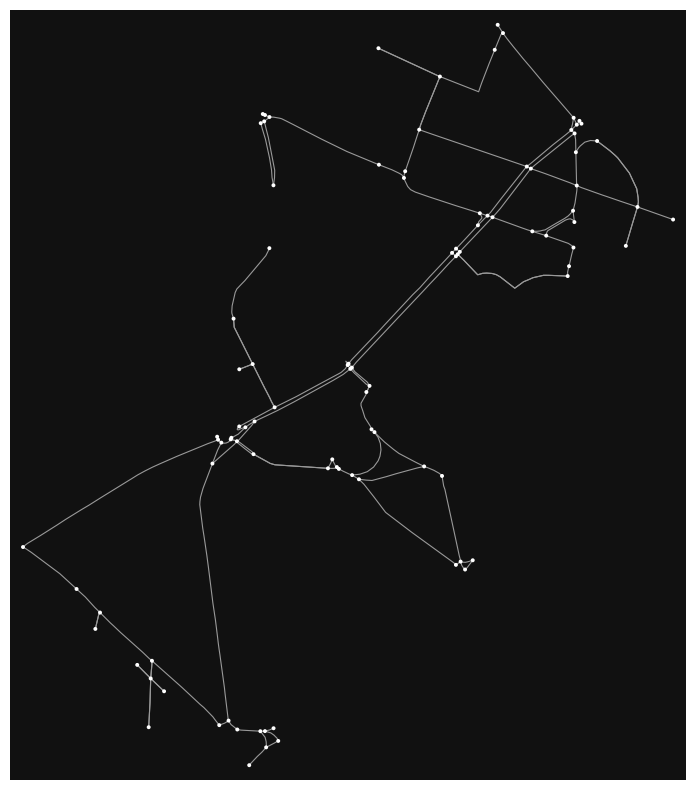

In [49]:
fig, ax = ox.plot_graph(
    G_demo,
    node_size=8,
    edge_linewidth=0.8,
    figsize=(10, 10)
)

plt.show()

In [51]:
print("Total demo nodes:", len(G_demo.nodes))

node_list = list(G_demo.nodes)

print("First 10 nodes:")
print(node_list[:10])

Total demo nodes: 99
First 10 nodes:
[12141911042, 12141911043, 249081348, 12141911045, 428831251, 428831259, 4017403934, 263156256, 428831267, 3641907748]


In [52]:
# Pick 9 nodes spread across the demo graph
sample_nodes = np.linspace(
    0,
    len(node_list) - 1,
    9,
    dtype=int
)

selected_nodes = [node_list[i] for i in sample_nodes]

DEPOT_BLR = selected_nodes[0]
DESTINATIONS_BLR = selected_nodes[1:]

print("Depot:", DEPOT_BLR)
print("Destinations:", DESTINATIONS_BLR)

Depot: 12141911042
Destinations: [663596583, 461789835, 249082069, 3461288201, 12143506753, 663311727, 11769490827, 1523537403]


In [53]:
print("\nDepot coordinates:")
print(
    G_demo.nodes[DEPOT_BLR]["y"],
    G_demo.nodes[DEPOT_BLR]["x"]
)

print("\nDestination coordinates:")

for i, node in enumerate(DESTINATIONS_BLR, 1):
    print(
        f"Destination {i}:",
        node,
        "->",
        G_demo.nodes[node]["y"],
        G_demo.nodes[node]["x"]
    )


Depot coordinates:
12.9758162 77.5874399

Destination coordinates:
Destination 1: 663596583 -> 12.9817267 77.5970852
Destination 2: 461789835 -> 12.986447 77.594845
Destination 3: 249082069 -> 12.9839484 77.5977237
Destination 4: 3461288201 -> 12.9827346 77.5886226
Destination 5: 12143506753 -> 12.9846608 77.5883841
Destination 6: 663311727 -> 12.9772392 77.5913243
Destination 7: 11769490827 -> 12.9844368 77.588265
Destination 8: 1523537403 -> 12.9845847 77.5970634


In [54]:
print(type(G_demo))
print("Nodes:", len(G_demo.nodes))
print("Edges:", len(G_demo.edges))

<class 'networkx.classes.multidigraph.MultiDiGraph'>
Nodes: 99
Edges: 142


In [55]:
DEPOT_BLR = 12141911042

DESTINATIONS_BLR = [
    663596583,
    461789835,
    249082069,
    3461288201,
    12143506753,
    663311727,
    11769490827,
    1523537403
]

IMPORTANT_NODES = [DEPOT_BLR] + DESTINATIONS_BLR

print("Depot:", DEPOT_BLR)
print("Number of destinations:", len(DESTINATIONS_BLR))
print("Total important nodes:", len(IMPORTANT_NODES))

Depot: 12141911042
Number of destinations: 8
Total important nodes: 9


In [56]:
distance_matrix = np.zeros((len(IMPORTANT_NODES), len(IMPORTANT_NODES)))

for i, source in enumerate(IMPORTANT_NODES):
    for j, target in enumerate(IMPORTANT_NODES):

        if source == target:
            distance_matrix[i][j] = 0
        else:
            try:
                distance_matrix[i][j] = nx.shortest_path_length(
                    G_demo,
                    source,
                    target,
                    weight="length"
                )
            except nx.NetworkXNoPath:
                distance_matrix[i][j] = np.inf

In [57]:
print(distance_matrix)

[[   0.                   inf           inf           inf           inf
            inf           inf           inf           inf]
 [          inf    0.                   inf           inf           inf
            inf           inf           inf           inf]
 [          inf           inf    0.                   inf           inf
            inf           inf           inf           inf]
 [1584.98351775  294.05281121 1428.29565404    0.         1509.1692431
  1304.92226695 1236.61640535 1322.5829398   952.36650306]
 [          inf           inf           inf           inf    0.
            inf           inf  193.63583398           inf]
 [          inf           inf           inf           inf           inf
     0.                   inf           inf           inf]
 [ 498.88485435 1183.74519644 1573.51903088 1515.75882765 1654.39261994
  1450.14564379    0.         1467.80631664 1121.55145065]
 [          inf           inf           inf           inf           inf
            inf     

In [58]:
print("Distance Matrix (meters):\n")

for i in range(len(IMPORTANT_NODES)):
    print(
        f"{i}:",
        [round(x, 1) if np.isfinite(x) else "INF"
         for x in distance_matrix[i]]
    )

Distance Matrix (meters):

0: [np.float64(0.0), 'INF', 'INF', 'INF', 'INF', 'INF', 'INF', 'INF', 'INF']
1: ['INF', np.float64(0.0), 'INF', 'INF', 'INF', 'INF', 'INF', 'INF', 'INF']
2: ['INF', 'INF', np.float64(0.0), 'INF', 'INF', 'INF', 'INF', 'INF', 'INF']
3: [np.float64(1585.0), np.float64(294.1), np.float64(1428.3), np.float64(0.0), np.float64(1509.2), np.float64(1304.9), np.float64(1236.6), np.float64(1322.6), np.float64(952.4)]
4: ['INF', 'INF', 'INF', 'INF', np.float64(0.0), 'INF', 'INF', np.float64(193.6), 'INF']
5: ['INF', 'INF', 'INF', 'INF', 'INF', np.float64(0.0), 'INF', 'INF', 'INF']
6: [np.float64(498.9), np.float64(1183.7), np.float64(1573.5), np.float64(1515.8), np.float64(1654.4), np.float64(1450.1), np.float64(0.0), np.float64(1467.8), np.float64(1121.6)]
7: ['INF', 'INF', 'INF', 'INF', 'INF', 'INF', 'INF', np.float64(0.0), 'INF']
8: ['INF', 'INF', 'INF', 'INF', 'INF', 'INF', 'INF', 'INF', np.float64(0.0)]


In [60]:
print("Original graph nodes:", len(G.nodes))
print("Original graph edges:", len(G.edges))

print("Connected components:",
      nx.number_connected_components(G))

Original graph nodes: 10
Original graph edges: 16
Connected components: 1


In [61]:
components = list(nx.connected_components(G))

print("Number of components:", len(components))

for i, component in enumerate(components[:10]):
    print(f"Component {i+1}: {len(component)} nodes")

Number of components: 1
Component 1: 10 nodes


In [63]:
print("G nodes:", len(G.nodes))
print("G_demo nodes:", len(G_demo.nodes))

IMPORTANT_NODES = [DEPOT_BLR] + DESTINATIONS_BLR

print("\nChecking nodes in G_demo:")

for node in IMPORTANT_NODES:
    print(node, "->", node in G_demo)

G nodes: 10
G_demo nodes: 99

Checking nodes in G_demo:
12141911042 -> True
663596583 -> True
461789835 -> True
249082069 -> True
3461288201 -> True
12143506753 -> True
663311727 -> True
11769490827 -> True
1523537403 -> True


In [65]:
print("G_demo nodes:", len(G_demo.nodes))
print("G_demo edges:", len(G_demo.edges))

print("Weakly connected components:",
      nx.number_weakly_connected_components(G_demo))

print("Strongly connected components:",
      nx.number_strongly_connected_components(G_demo))

G_demo nodes: 99
G_demo edges: 142
Weakly connected components: 1
Strongly connected components: 50


In [66]:
IMPORTANT_NODES = [DEPOT_BLR] + DESTINATIONS_BLR

for node in IMPORTANT_NODES:
    component = nx.node_connected_component(
        G_demo.to_undirected(),
        node
    )
    print(node, "-> component size:", len(component))

12141911042 -> component size: 99
663596583 -> component size: 99
461789835 -> component size: 99
249082069 -> component size: 99
3461288201 -> component size: 99
12143506753 -> component size: 99
663311727 -> component size: 99
11769490827 -> component size: 99
1523537403 -> component size: 99


In [67]:
print("G_demo type:", type(G_demo))

print("\nDirected reachability from depot:")

for node in IMPORTANT_NODES:
    reachable = nx.has_path(G_demo, DEPOT_BLR, node)
    print(DEPOT_BLR, "->", node, ":", reachable)

G_demo type: <class 'networkx.classes.multidigraph.MultiDiGraph'>

Directed reachability from depot:
12141911042 -> 12141911042 : True
12141911042 -> 663596583 : False
12141911042 -> 461789835 : False
12141911042 -> 249082069 : False
12141911042 -> 3461288201 : False
12141911042 -> 12143506753 : False
12141911042 -> 663311727 : False
12141911042 -> 11769490827 : False
12141911042 -> 1523537403 : False


In [68]:
print("\nDirected reachability back to depot:")

for node in IMPORTANT_NODES:
    reachable = nx.has_path(G_demo, node, DEPOT_BLR)
    print(node, "->", DEPOT_BLR, ":", reachable)


Directed reachability back to depot:
12141911042 -> 12141911042 : True
663596583 -> 12141911042 : False
461789835 -> 12141911042 : False
249082069 -> 12141911042 : True
3461288201 -> 12141911042 : False
12143506753 -> 12141911042 : False
663311727 -> 12141911042 : True
11769490827 -> 12141911042 : False
1523537403 -> 12141911042 : False


In [69]:
IMPORTANT_NODES = [DEPOT_BLR] + DESTINATIONS_BLR

print("Checking important nodes in FULL graph:\n")

for node in IMPORTANT_NODES:
    print(node, "->", node in G)

Checking important nodes in FULL graph:

12141911042 -> False
663596583 -> False
461789835 -> False
249082069 -> False
3461288201 -> False
12143506753 -> False
663311727 -> False
11769490827 -> False
1523537403 -> False


In [70]:
print("FULL GRAPH")
print("Nodes:", len(G.nodes))
print("Edges:", len(G.edges))

print("\nImportant nodes present in FULL graph:")

for node in IMPORTANT_NODES:
    print(node, "->", node in G)

FULL GRAPH
Nodes: 10
Edges: 16

Important nodes present in FULL graph:
12141911042 -> False
663596583 -> False
461789835 -> False
249082069 -> False
3461288201 -> False
12143506753 -> False
663311727 -> False
11769490827 -> False
1523537403 -> False


In [72]:
print("Full graph nodes:", len(G.nodes))

print("\nChecking important nodes:")

for node in [DEPOT_BLR] + DESTINATIONS_BLR:
    print(node, "->", node in G)

Full graph nodes: 10

Checking important nodes:
12141911042 -> False
663596583 -> False
461789835 -> False
249082069 -> False
3461288201 -> False
12143506753 -> False
663311727 -> False
11769490827 -> False
1523537403 -> False


In [73]:
print("Depot:", DEPOT_BLR, DEPOT_BLR in G)

for node in DESTINATIONS_BLR:
    print("Destination:", node, node in G)

Depot: 12141911042 False
Destination: 663596583 False
Destination: 461789835 False
Destination: 249082069 False
Destination: 3461288201 False
Destination: 12143506753 False
Destination: 663311727 False
Destination: 11769490827 False
Destination: 1523537403 False


In [74]:
print("G nodes:", len(G.nodes))
print("G edges:", len(G.edges))

print("\nFirst 20 nodes in G:")
print(list(G.nodes)[:20])

G nodes: 10
G edges: 16

First 20 nodes in G:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [75]:
print("\nDepot from G_demo:")
print(DEPOT_BLR)

print("\nIs depot in G_demo?", DEPOT_BLR in G_demo)


Depot from G_demo:
12141911042

Is depot in G_demo? True


In [76]:
print("G_demo nodes:", len(G_demo.nodes))
print("G_demo edges:", len(G_demo.edges))

for node in [DEPOT_BLR] + DESTINATIONS_BLR:
    print(node, "->", node in G_demo)

G_demo nodes: 99
G_demo edges: 142
12141911042 -> True
663596583 -> True
461789835 -> True
249082069 -> True
3461288201 -> True
12143506753 -> True
663311727 -> True
11769490827 -> True
1523537403 -> True


In [77]:
print("FULL GRAPH")
print("Nodes:", len(G.nodes))
print("Edges:", len(G.edges))

print("\nSample nodes:")
print(list(G.nodes)[:20])

FULL GRAPH
Nodes: 10
Edges: 16

Sample nodes:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [78]:
print("G_demo:", len(G_demo.nodes), "nodes")

G_demo: 99 nodes


In [79]:
[name for name in globals() if name.startswith("G")]

['G', 'G_bangalore', 'G_connected', 'G_demo']

In [80]:
print("G:", len(G.nodes), "nodes,", len(G.edges), "edges")
print("G_bangalore:", len(G_bangalore.nodes), "nodes,", len(G_bangalore.edges), "edges")
print("G_connected:", len(G_connected.nodes), "nodes,", len(G_connected.edges), "edges")
print("G_demo:", len(G_demo.nodes), "nodes,", len(G_demo.edges), "edges")

G: 10 nodes, 16 edges
G_bangalore: 155564 nodes, 393951 edges
G_connected: 155564 nodes, 393951 edges
G_demo: 99 nodes, 142 edges


In [81]:
G_BLR = G_connected

print("G_BLR nodes:", len(G_BLR.nodes))
print("G_BLR edges:", len(G_BLR.edges))

G_BLR nodes: 155564
G_BLR edges: 393951


In [82]:
DEPOT_BLR = 12141911042

DESTINATIONS_BLR = [
    663596583,
    461789835,
    249082069,
    3461288201,
    12143506753,
    663311727,
    11769490827,
    1523537403
]

print("Depot exists:", DEPOT_BLR in G_BLR)

for node in DESTINATIONS_BLR:
    print(node, "exists:", node in G_BLR)

Depot exists: True
663596583 exists: True
461789835 exists: True
249082069 exists: True
3461288201 exists: True
12143506753 exists: True
663311727 exists: True
11769490827 exists: True
1523537403 exists: True


In [83]:
print("DEPOT → DESTINATIONS")
print("-" * 40)

for node in DESTINATIONS_BLR:
    try:
        d = nx.shortest_path_length(
            G_BLR,
            source=DEPOT_BLR,
            target=node,
            weight="length"
        )
        print(node, "→", round(d, 2), "meters")
    except nx.NetworkXNoPath:
        print(node, "→ NO PATH")

DEPOT → DESTINATIONS
----------------------------------------
663596583 → 1622.09 meters
461789835 → 2011.86 meters
249082069 → 1954.1 meters
3461288201 → 1019.24 meters
12143506753 → 1243.61 meters
663311727 → 618.42 meters
11769490827 → 1212.88 meters
1523537403 → 1559.89 meters


In [84]:
print("\nDESTINATIONS → DEPOT")
print("-" * 40)

for node in DESTINATIONS_BLR:
    try:
        d = nx.shortest_path_length(
            G_BLR,
            source=node,
            target=DEPOT_BLR,
            weight="length"
        )
        print(node, "→", round(d, 2), "meters")
    except nx.NetworkXNoPath:
        print(node, "→ NO PATH")


DESTINATIONS → DEPOT
----------------------------------------
663596583 → 1458.95 meters
461789835 → 2416.83 meters
249082069 → 1507.02 meters
3461288201 → 1310.93 meters
12143506753 → 1269.94 meters
663311727 → 498.88 meters
11769490827 → 1239.4 meters
1523537403 → 2695.13 meters


In [85]:
ALL_NODES = [DEPOT_BLR] + DESTINATIONS_BLR

distance_matrix = np.zeros((len(ALL_NODES), len(ALL_NODES)))

for i, source in enumerate(ALL_NODES):
    for j, target in enumerate(ALL_NODES):
        if source == target:
            distance_matrix[i][j] = 0
        else:
            try:
                distance_matrix[i][j] = nx.shortest_path_length(
                    G_BLR,
                    source=source,
                    target=target,
                    weight="length"
                )
            except nx.NetworkXNoPath:
                distance_matrix[i][j] = np.inf

print("Distance matrix shape:", distance_matrix.shape)
print(distance_matrix)

Distance matrix shape: (9, 9)
[[   0.         1622.08646174 2011.86029617 1954.10009295 1019.23927827
  1243.61021704  618.42103283 1212.87511225 1559.89271595]
 [1458.9460881     0.         1302.25822439  557.6708803  1383.13181345
  1178.88483731 1110.5789757  1196.54551016  660.87082341]
 [2416.83479817 1681.34537829    0.         2013.3590095  1402.57177434
  1201.02055798 2313.85737092 1215.98547104 1530.20089001]
 [1507.01915744  294.05281121  779.80017158    0.         1431.20488279
  1226.95790664 1158.65204504 1244.6185795   103.1999431 ]
 [1310.9338752  1741.04031313 1556.1987651  2073.05394434    0.
   224.37093877 1110.2303005   193.63583398 1678.84656735]
 [1269.9375219  1516.66937437 1331.82782634 1848.68300558  255.67449806
     0.         1365.90479856   69.08819477 1454.47562858]
 [ 498.88485435 1183.74519644 1573.51903088 1515.75882765 1353.37234078
  1450.14564379    0.         1467.80631664 1121.55145065]
 [1239.39601944 1547.40447915 1362.56293112 1879.41811036  23

In [86]:
print("\nDistance Matrix (meters)")
print("-" * 80)

for i, source in enumerate(ALL_NODES):
    print(f"{i}: ", end="")
    for j in range(len(ALL_NODES)):
        print(f"{distance_matrix[i][j]:8.1f}", end=" ")
    print()


Distance Matrix (meters)
--------------------------------------------------------------------------------
0:      0.0   1622.1   2011.9   1954.1   1019.2   1243.6    618.4   1212.9   1559.9 
1:   1458.9      0.0   1302.3    557.7   1383.1   1178.9   1110.6   1196.5    660.9 
2:   2416.8   1681.3      0.0   2013.4   1402.6   1201.0   2313.9   1216.0   1530.2 
3:   1507.0    294.1    779.8      0.0   1431.2   1227.0   1158.7   1244.6    103.2 
4:   1310.9   1741.0   1556.2   2073.1      0.0    224.4   1110.2    193.6   1678.8 
5:   1269.9   1516.7   1331.8   1848.7    255.7      0.0   1365.9     69.1   1454.5 
6:    498.9   1183.7   1573.5   1515.8   1353.4   1450.1      0.0   1467.8   1121.6 
7:   1239.4   1547.4   1362.6   1879.4    232.3     30.7   1342.5      0.0   1485.2 
8:   2695.1   1959.6    676.6   2291.7   1680.9   1479.3   2592.2   1494.3      0.0 


In [87]:
node_to_index = {
    node: i
    for i, node in enumerate(ALL_NODES)
}

index_to_node = {
    i: node
    for i, node in enumerate(ALL_NODES)
}

print(node_to_index)

{12141911042: 0, 663596583: 1, 461789835: 2, 249082069: 3, 3461288201: 4, 12143506753: 5, 663311727: 6, 11769490827: 7, 1523537403: 8}


In [88]:
def route_distance_matrix(route, distance_matrix):
    total = 0

    for i in range(len(route) - 1):
        total += distance_matrix[route[i]][route[i + 1]]

    return total

In [89]:
test_route = [0, 1, 3, 6, 0]

distance = route_distance_matrix(test_route, distance_matrix)

print("Test route:", test_route)
print("Distance:", round(distance, 2), "meters")
print("Distance:", round(distance / 1000, 3), "km")

Test route: [0, 1, 3, 6, 0]
Distance: 3837.29 meters
Distance: 3.837 km


In [90]:
def route_distance_matrix(route, distance_matrix):
    total = 0

    for i in range(len(route) - 1):
        total += distance_matrix[route[i]][route[i + 1]]

    return total

In [91]:
def fleet_fitness(routes, distance_matrix):
    total = 0

    for route in routes:
        total += route_distance_matrix(route, distance_matrix)

    return total

In [92]:
test_routes = [
    [0, 1, 0],
    [0, 2, 0],
    [0, 3, 6, 0],
    [0, 4, 0],
    [0, 5, 7, 8, 0]
]

total = fleet_fitness(test_routes, distance_matrix)

print("Test fleet routes:")
for i, route in enumerate(test_routes, 1):
    print(f"Vehicle {i}: {route}")

print("\nTotal fleet distance:", round(total, 2), "meters")
print("Total fleet distance:", round(total / 1000, 3), "km")

Test fleet routes:
Vehicle 1: [0, 1, 0]
Vehicle 2: [0, 2, 0]
Vehicle 3: [0, 3, 6, 0]
Vehicle 4: [0, 4, 0]
Vehicle 5: [0, 5, 7, 8, 0]

Total fleet distance: 18944.58 meters
Total fleet distance: 18.945 km


In [94]:
def route_distance_matrix(route, distance_matrix):
    total = 0

    for i in range(len(route) - 1):
        total += distance_matrix[route[i]][route[i + 1]]

    return total


def fleet_fitness(routes, distance_matrix):
    total = 0

    for route in routes:
        total += route_distance_matrix(route, distance_matrix)

    return total

In [96]:
test_position = np.random.rand(16)

test_routes = particle_to_routes(
    test_position,
    list(range(1, 9)),
    5,
    depot=0
)

test_routes

[[0, 7, 0], [0, 6, 0], [0, 2, 8, 0], [0, 3, 5, 0], [0, 4, 1, 0]]

In [97]:
NUM_DESTINATIONS = 8
NUM_VEHICLES = 5

DIMENSION = NUM_DESTINATIONS * 2

NUM_PARTICLES = 25
MAX_ITERATIONS = 150

BETA_MAX = 1.0
BETA_MIN = 0.5

In [98]:
def particle_to_routes(position, destinations, num_vehicles, depot=0):

    n = len(destinations)

    # First 8 values → destination ordering
    order_values = position[:n]

    # Next 8 values → vehicle assignment
    vehicle_values = position[n:2*n]

    # SPV ordering
    sorted_indices = np.argsort(order_values)

    ordered_destinations = [
        destinations[i] for i in sorted_indices
    ]

    # Convert values into vehicle numbers
    assignments = np.floor(
        vehicle_values * num_vehicles
    ).astype(int)

    assignments = np.clip(
        assignments, 0, num_vehicles - 1
    )

    routes = [[] for _ in range(num_vehicles)]

    # Assign destinations
    for i, destination in enumerate(destinations):

        vehicle_index = assignments[i]

        routes[vehicle_index].append(destination)

    # Add depot
    final_routes = []

    for route in routes:

        if len(route) > 0:
            final_route = [depot] + route + [depot]
        else:
            final_route = [depot]

        final_routes.append(final_route)

    return final_routes

In [99]:
test_position = np.random.rand(16)

test_routes = particle_to_routes(
    test_position,
    list(range(1, 9)),
    5
)

test_routes

[[0, 8, 0], [0, 5, 0], [0], [0, 1, 3, 4, 6, 0], [0, 2, 7, 0]]

In [100]:
test_distance = fleet_fitness(
    test_routes,
    distance_matrix
)

print("Test fleet distance:", test_distance, "meters")
print("Test fleet distance:", test_distance / 1000, "km")

Test fleet distance: 16455.88811546895 meters
Test fleet distance: 16.45588811546895 km


In [109]:
def qpso_16d(
    destinations,
    num_vehicles,
    distance_matrix,
    num_particles=25,
    max_iterations=150,
    beta_max=1.0,
    beta_min=0.5
):

    dimension = len(destinations) * 2

    # Initialize particles
    positions = np.random.rand(num_particles, dimension)

    # Personal best positions
    pbest_positions = positions.copy()

    # Personal best fitness
    pbest_fitness = np.full(num_particles, np.inf)

    # Evaluate initial particles
    for i in range(num_particles):

        routes = particle_to_routes(
            positions[i],
            destinations,
            num_vehicles
        )

        pbest_fitness[i] = fleet_fitness(
            routes,
            distance_matrix
        )

    # Global best
    best_index = np.argmin(pbest_fitness)

    gbest_position = pbest_positions[best_index].copy()
    gbest_fitness = pbest_fitness[best_index]

    # Store convergence
    convergence = []

    # QPSO iterations
    for iteration in range(max_iterations):

        # Adaptive beta
        beta = beta_max - (
            (beta_max - beta_min)
            * iteration
            / max_iterations
        )

        # MBEST
        mbest = np.mean(
            pbest_positions,
            axis=0
        )

        # Update every particle
        for i in range(num_particles):

            position = positions[i]

            # Random phi
            phi = np.random.rand(dimension)

            # Attractor point
            p = (
                phi * pbest_positions[i]
                + (1 - phi) * gbest_position
            )

            # Random values
            u = np.random.rand(dimension)

            # Random direction
            direction = np.where(
                np.random.rand(dimension) < 0.5,
                -1,
                1
            )

            # Quantum position update
            new_position = (
                p
                + direction
                * beta
                * np.abs(mbest - position)
                * np.log(1 / u)
            )

            # Keep values between 0 and 1
            new_position = np.clip(
                new_position,
                0,
                1
            )

            positions[i] = new_position

            # Evaluate new particle
            routes = particle_to_routes(
                new_position,
                destinations,
                num_vehicles
            )

            current_fitness = fleet_fitness(
                routes,
                distance_matrix
            )

            # Update personal best
            if current_fitness < pbest_fitness[i]:

                pbest_fitness[i] = current_fitness
                pbest_positions[i] = new_position.copy()

                # Update global best
                if current_fitness < gbest_fitness:

                    gbest_fitness = current_fitness
                    gbest_position = new_position.copy()

        convergence.append(gbest_fitness)

        if iteration % 10 == 0:

            print(
                f"Iteration {iteration:3d} | "
                f"Beta = {beta:.3f} | "
                f"Best = {gbest_fitness:.2f} m"
            )

    # Decode final solution
    best_routes = particle_to_routes(
        gbest_position,
        destinations,
        num_vehicles
    )

    return (
        gbest_position,
        best_routes,
        gbest_fitness,
        convergence
    )
    

In [110]:
best_distance = fleet_fitness(
    best_routes,
    distance_matrix
)

print(f"Total fleet distance: {best_distance:.2f} meters")
print(f"Total fleet distance: {best_distance/1000:.3f} km")

Total fleet distance: 19334.79 meters
Total fleet distance: 19.335 km


In [104]:
print("\nFINAL QPSO RESULT")

for i, route in enumerate(best_routes):
    print(f"Vehicle {i+1}: {route}")

print(f"\nTotal fleet distance: {best_distance:.2f} meters")
print(f"Total fleet distance: {best_distance/1000:.3f} km")


FINAL QPSO RESULT
Vehicle 1: [0, 4, 0]
Vehicle 2: [0, 2, 0]
Vehicle 3: [0, 5, 8, 7, 6, 0]
Vehicle 4: [0, 3, 0]
Vehicle 5: [0, 1, 0]

Total fleet distance: 19334.79 meters
Total fleet distance: 19.335 km


In [108]:
test_position = np.random.rand(16)

test_routes = particle_to_routes(
    test_position,
    list(range(1, 9)),
    5,
    depot=0
)

test_routes

[[0, 6, 0], [0, 7, 0], [0, 8, 2, 0], [0, 4, 5, 3, 0], [0, 1, 0]]

In [112]:
def particle_to_routes(position, destinations, num_vehicles, depot=0):
    
    n = len(destinations)

    # First n values → destination ordering
    order_values = position[:n]

    # Next n values → vehicle assignment
    vehicle_values = position[n:2*n]

    # SPV: sort destinations according to order values
    sorted_indices = np.argsort(order_values)

    # Convert values into vehicle numbers
    assignments = np.floor(
        vehicle_values * num_vehicles
    ).astype(int)

    assignments = np.clip(
        assignments,
        0,
        num_vehicles - 1
    )

    routes = [[] for _ in range(num_vehicles)]

    # Add destinations in SPV order
    for idx in sorted_indices:
        destination = destinations[idx]
        vehicle_index = assignments[idx]
        routes[vehicle_index].append(destination)

    final_routes = []

    for route in routes:
        if len(route) > 0:
            final_route = [depot] + route + [depot]
        else:
            final_route = [depot]

        final_routes.append(final_route)

    return final_routes

In [113]:
def qpso_16d(distance_matrix, destinations, num_vehicles):

    n = len(destinations)
    dimension = n * 2

    num_particles = 25
    max_iterations = 150

    beta_max = 1.0
    beta_min = 0.5

    # Initial particle positions
    positions = np.random.rand(num_particles, dimension)

    # Personal best
    pbest_positions = positions.copy()
    pbest_fitness = np.full(num_particles, np.inf)

    # Global best
    gbest_position = None
    gbest_fitness = np.inf

    convergence = []

    # Evaluate initial population
    for i in range(num_particles):

        routes = particle_to_routes(
            positions[i],
            destinations,
            num_vehicles
        )

        fitness = fleet_fitness(
            routes,
            distance_matrix
        )

        pbest_fitness[i] = fitness

        if fitness < gbest_fitness:
            gbest_fitness = fitness
            gbest_position = positions[i].copy()

    # QPSO iterations
    for iteration in range(max_iterations):

        # Linearly decreasing beta
        beta = beta_max - (
            beta_max - beta_min
        ) * iteration / max_iterations

        # MBEST
        mbest = np.mean(
            pbest_positions,
            axis=0
        )

        for i in range(num_particles):

            # Random number
            u = np.random.rand(dimension)

            # Random attractor weight
            phi = np.random.rand(dimension)

            # Attractor
            p = (
                phi * pbest_positions[i]
                + (1 - phi) * gbest_position
            )

            # Random direction
            sign = np.where(
                np.random.rand(dimension) < 0.5,
                -1,
                1
            )

            # Quantum-inspired position update
            positions[i] = (
                p
                + sign
                * beta
                * np.abs(mbest - positions[i])
                * np.log(1 / u)
            )

            # Keep values inside [0,1]
            positions[i] = np.clip(
                positions[i],
                0,
                1
            )

            # Evaluate new position
            routes = particle_to_routes(
                positions[i],
                destinations,
                num_vehicles
            )

            fitness = fleet_fitness(
                routes,
                distance_matrix
            )

            # Update personal best
            if fitness < pbest_fitness[i]:

                pbest_fitness[i] = fitness
                pbest_positions[i] = positions[i].copy()

            # Update global best
            if fitness < gbest_fitness:

                gbest_fitness = fitness
                gbest_position = positions[i].copy()

        convergence.append(gbest_fitness)

        if iteration % 10 == 0:
            print(
                f"Iteration {iteration} | "
                f"Beta = {beta:.3f} | "
                f"Best Distance = {gbest_fitness:.2f}"
            )

    best_routes = particle_to_routes(
        gbest_position,
        destinations,
        num_vehicles
    )

    return (
        gbest_position,
        best_routes,
        gbest_fitness,
        convergence
    )

In [114]:
best_position, best_routes, best_distance, convergence = qpso_16d(
    distance_matrix,
    DESTINATIONS_BLR,
    NUM_VEHICLES
)

IndexError: index 12143506753 is out of bounds for axis 0 with size 9

In [115]:
DESTINATIONS_INDEX = list(range(1, 9))

print(DESTINATIONS_INDEX)

[1, 2, 3, 4, 5, 6, 7, 8]


In [116]:
best_position, best_routes, best_distance, convergence = qpso_16d(
    distance_matrix,
    DESTINATIONS_INDEX,
    NUM_VEHICLES
)

Iteration 0 | Beta = 1.000 | Best Distance = 12460.13
Iteration 10 | Beta = 0.967 | Best Distance = 11430.09
Iteration 20 | Beta = 0.933 | Best Distance = 11430.09
Iteration 30 | Beta = 0.900 | Best Distance = 10767.57
Iteration 40 | Beta = 0.867 | Best Distance = 8495.94
Iteration 50 | Beta = 0.833 | Best Distance = 8070.02
Iteration 60 | Beta = 0.800 | Best Distance = 8070.02
Iteration 70 | Beta = 0.767 | Best Distance = 8070.02
Iteration 80 | Beta = 0.733 | Best Distance = 8070.02
Iteration 90 | Beta = 0.700 | Best Distance = 8062.87
Iteration 100 | Beta = 0.667 | Best Distance = 8062.87
Iteration 110 | Beta = 0.633 | Best Distance = 8062.87
Iteration 120 | Beta = 0.600 | Best Distance = 8062.87
Iteration 130 | Beta = 0.567 | Best Distance = 8062.87
Iteration 140 | Beta = 0.533 | Best Distance = 8062.87


In [117]:
print("Best QPSO Routes:")

for i, route in enumerate(best_routes):
    print(f"Vehicle {i+1}: {route}")

print(f"\nBest fleet distance: {best_distance:.2f} meters")
print(f"Best fleet distance: {best_distance/1000:.3f} km")

Best QPSO Routes:
Vehicle 1: [0]
Vehicle 2: [0, 4, 7, 0]
Vehicle 3: [0, 6, 1, 3, 8, 2, 5, 0]
Vehicle 4: [0]
Vehicle 5: [0]

Best fleet distance: 8062.87 meters
Best fleet distance: 8.063 km


In [118]:
def particle_to_routes(position, destinations, num_vehicles, depot=0):

    n = len(destinations)

    # First n values → destination ordering
    order_values = position[:n]

    # Next n values → vehicle assignment
    vehicle_values = position[n:2*n]

    # SPV ordering
    sorted_indices = np.argsort(order_values)

    # Initial vehicle assignments
    assignments = np.floor(
        vehicle_values * num_vehicles
    ).astype(int)

    assignments = np.clip(
        assignments,
        0,
        num_vehicles - 1
    )

    # Make sure every vehicle gets at least one destination
    used_vehicles = set(assignments)

    missing_vehicles = [
        v for v in range(num_vehicles)
        if v not in used_vehicles
    ]

    for missing_vehicle in missing_vehicles:

        # Find a vehicle having more than one destination
        counts = np.bincount(
            assignments,
            minlength=num_vehicles
        )

        donor_candidates = [
            v for v in range(num_vehicles)
            if counts[v] > 1
        ]

        if donor_candidates:

            # Take a destination from the largest vehicle
            donor = max(
                donor_candidates,
                key=lambda v: counts[v]
            )

            donor_indices = np.where(
                assignments == donor
            )[0]

            moved_destination = donor_indices[-1]

            assignments[moved_destination] = missing_vehicle

    # Build routes following SPV order
    routes = [[] for _ in range(num_vehicles)]

    for idx in sorted_indices:

        destination = destinations[idx]
        vehicle = assignments[idx]

        routes[vehicle].append(destination)

    # Add depot at beginning and end
    final_routes = []

    for route in routes:

        final_route = [depot] + route + [depot]

        final_routes.append(final_route)

    return final_routes

In [119]:
test_position = np.random.rand(16)

test_routes = particle_to_routes(
    test_position,
    DESTINATIONS_INDEX,
    NUM_VEHICLES
)

for i, route in enumerate(test_routes):
    print(f"Vehicle {i+1}: {route}")

Vehicle 1: [0, 3, 0]
Vehicle 2: [0, 1, 0]
Vehicle 3: [0, 8, 7, 4, 0]
Vehicle 4: [0, 6, 0]
Vehicle 5: [0, 2, 5, 0]


In [120]:
best_position, best_routes, best_distance, convergence = qpso_16d(
    distance_matrix,
    DESTINATIONS_INDEX,
    NUM_VEHICLES
)

Iteration 0 | Beta = 1.000 | Best Distance = 16032.81
Iteration 10 | Beta = 0.967 | Best Distance = 15802.31
Iteration 20 | Beta = 0.933 | Best Distance = 15802.31
Iteration 30 | Beta = 0.900 | Best Distance = 14231.34
Iteration 40 | Beta = 0.867 | Best Distance = 14192.79
Iteration 50 | Beta = 0.833 | Best Distance = 14192.79
Iteration 60 | Beta = 0.800 | Best Distance = 14192.79
Iteration 70 | Beta = 0.767 | Best Distance = 14192.79
Iteration 80 | Beta = 0.733 | Best Distance = 14185.64
Iteration 90 | Beta = 0.700 | Best Distance = 14185.64
Iteration 100 | Beta = 0.667 | Best Distance = 14185.64
Iteration 110 | Beta = 0.633 | Best Distance = 14185.64
Iteration 120 | Beta = 0.600 | Best Distance = 14185.64
Iteration 130 | Beta = 0.567 | Best Distance = 14185.64
Iteration 140 | Beta = 0.533 | Best Distance = 14185.64


In [121]:
print("Best QPSO Routes:")

for i, route in enumerate(best_routes):
    print(f"Vehicle {i+1}: {route}")

print(f"\nBest fleet distance: {best_distance:.2f} meters")
print(f"Best fleet distance: {best_distance/1000:.3f} km")

Best QPSO Routes:
Vehicle 1: [0, 1, 0]
Vehicle 2: [0, 6, 0]
Vehicle 3: [0, 3, 8, 2, 5, 0]
Vehicle 4: [0, 7, 0]
Vehicle 5: [0, 4, 0]

Best fleet distance: 14185.64 meters
Best fleet distance: 14.186 km


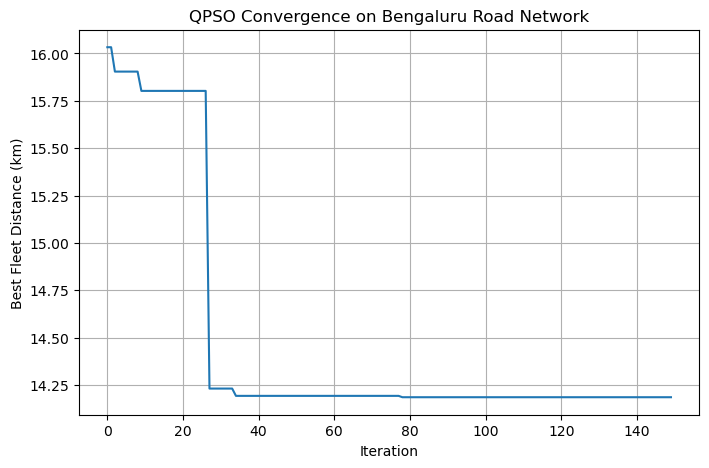

In [122]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    np.array(convergence) / 1000
)

plt.xlabel("Iteration")
plt.ylabel("Best Fleet Distance (km)")
plt.title("QPSO Convergence on Bengaluru Road Network")
plt.grid(True)

plt.show()

In [123]:
def pso_16d(distance_matrix, destinations, num_vehicles):

    n = len(destinations)
    dimension = n * 2

    num_particles = 25
    max_iterations = 150

    w = 0.7
    c1 = 1.5
    c2 = 1.5

    # Initial positions and velocities
    positions = np.random.rand(num_particles, dimension)
    velocities = np.random.uniform(
        -0.1, 0.1,
        size=(num_particles, dimension)
    )

    # Personal best
    pbest_positions = positions.copy()
    pbest_fitness = np.full(num_particles, np.inf)

    # Global best
    gbest_position = None
    gbest_fitness = np.inf

    convergence = []

    # Initial evaluation
    for i in range(num_particles):

        routes = particle_to_routes(
            positions[i],
            destinations,
            num_vehicles
        )

        fitness = fleet_fitness(
            routes,
            distance_matrix
        )

        pbest_fitness[i] = fitness

        if fitness < gbest_fitness:
            gbest_fitness = fitness
            gbest_position = positions[i].copy()

    # PSO iterations
    for iteration in range(max_iterations):

        for i in range(num_particles):

            r1 = np.random.rand(dimension)
            r2 = np.random.rand(dimension)

            velocities[i] = (
                w * velocities[i]
                + c1 * r1 * (
                    pbest_positions[i] - positions[i]
                )
                + c2 * r2 * (
                    gbest_position - positions[i]
                )
            )

            positions[i] += velocities[i]

            # Keep position values within [0,1]
            positions[i] = np.clip(
                positions[i],
                0,
                1
            )

            # Evaluate
            routes = particle_to_routes(
                positions[i],
                destinations,
                num_vehicles
            )

            fitness = fleet_fitness(
                routes,
                distance_matrix
            )

            # Personal best
            if fitness < pbest_fitness[i]:

                pbest_fitness[i] = fitness
                pbest_positions[i] = positions[i].copy()

            # Global best
            if fitness < gbest_fitness:

                gbest_fitness = fitness
                gbest_position = positions[i].copy()

        convergence.append(gbest_fitness)

        if iteration % 10 == 0:
            print(
                f"Iteration {iteration} | "
                f"Best Distance = {gbest_fitness:.2f}"
            )

    best_routes = particle_to_routes(
        gbest_position,
        destinations,
        num_vehicles
    )

    return (
        gbest_position,
        best_routes,
        gbest_fitness,
        convergence
    )

In [124]:
pso_position, pso_routes, pso_distance, pso_convergence = pso_16d(
    distance_matrix,
    DESTINATIONS_INDEX,
    NUM_VEHICLES
)

Iteration 0 | Best Distance = 15994.19
Iteration 10 | Best Distance = 15877.84
Iteration 20 | Best Distance = 15877.84
Iteration 30 | Best Distance = 15877.84
Iteration 40 | Best Distance = 15877.84
Iteration 50 | Best Distance = 15877.84
Iteration 60 | Best Distance = 15877.84
Iteration 70 | Best Distance = 15877.84
Iteration 80 | Best Distance = 15877.84
Iteration 90 | Best Distance = 15877.84
Iteration 100 | Best Distance = 15877.84
Iteration 110 | Best Distance = 15877.84
Iteration 120 | Best Distance = 15877.84
Iteration 130 | Best Distance = 15877.84
Iteration 140 | Best Distance = 15877.84


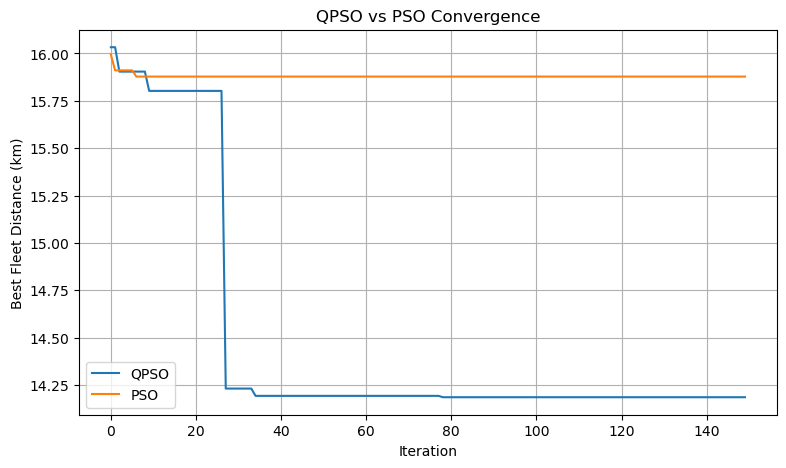

In [125]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.array(convergence) / 1000,
    label="QPSO"
)

plt.plot(
    np.array(pso_convergence) / 1000,
    label="PSO"
)

plt.xlabel("Iteration")
plt.ylabel("Best Fleet Distance (km)")
plt.title("QPSO vs PSO Convergence")
plt.legend()
plt.grid(True)

plt.show()